# Regresión Lineal

## Preparación

Para ejecutar el código de este Notebook es necesario importar algunas librerías ...

In [1]:
# To visualize plots in the notebook
%matplotlib inline

# Imported libraries
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy.io       # To read matlab files
import pylab

import sys

## Introduction

The objective of this practical session is to implement a number of methods for linear and semi-linear regression to predict the stock prices of an air company using as input variables the stock of their competitors during the same days. 

File DatosP1.mat contains the data to be used for this practice . After loading this file you can check that you will have six variables in your Matlab workspace:

*	`xTrain`: A matrix with observations containing the training data. The size of this matrix is 380 × 9, corresponding to 380 training patterns of length 9; i.e., each vector X consists of 9 different observations.
*	`sTrain`: A vector of length 380 with values of the target variable S for each of the training patterns. Data are arranged in the same order than xTrain. This means that the k-th element in sTrain contains the value of S corresponding to the k-th row of xTrain.
*	`xVal`: Matrix 380 × 9 containing the observations of the validation set.
*	`sVal`: Vector of length 380 with the values of the target variable S for each of the patterns in xVal.
*	`xTest`: Matrix 190×9 containing the observations of the test set.
*	`sTest`: Vector of length 190 with values of the target variable S for each of the patterns in  xTest.

Each row of matrices `xTrain`, `xVal` consists of the stock prices, in the same day, of 9 different airline companies. The objective of the estimators to design will be to predict the stock prize corresponding to a tenth airline company. In this practical session, estimators will be designed following a machine approach, for which we also have access to the real values of the target variable S corresponding to each row in the previous matrices. These values are stored in vectors `sTrain` and `sVal`, respectively.

For the design, we will use `xTrain` and `sTrain` to adjust the regression models, whereas `xVal` and `sVal` will be used to validate the models to guarantee that the constructed estimator generalizes well, i.e., it works correctly when applied to data different from the ones used during the design stage. 

Once the estimator has been designed, it will be possible to estimate unknown values of `S` given the corresponding observation vectors. During the session, you can use variables `xTest` and `sTest` to assess the generalization performance of the designs. 

The goals of this lab exercise are

*	Designing linear and polynomial estimators.
*	Analyze the feature selection problem.
*	To illustrate the concept of overfitting. Along the session, students will be able to check that an estimator with an excessive number of free parameters can lead to suboptimal performance with respect to generalization error.
*	To study how a validation set helps in the selection of an appropriate model that guarantees good generalization.



The dataset is an adaptation of the Stock dataset in http://www.dcc.fc.up.pt/~ltorgo/Regression/DataSets.html, taken originally from the StatLib Repository, in http://lib.stat.cmu.edu/.

## 1. Data visualization and normalization.

Load the data file, and consider by now just the training data.

In [2]:
data = scipy.io.loadmat('DatosP1.mat')
xTrain = data['xTrain']
xVal = data['xVal']
xTest = data['xTest']
sTrain = data['sTrain']
sVal = data['sVal']
sTest = data['sTest']

### a) Visualize the data set:

In order to get a first (though incomplete) view of the problem, represent graphically the value of the variable to be estimated, `s`, as a function of each feature, `xi` (i.e., the pairs `{xi(k), s(k)}` in the training data set).


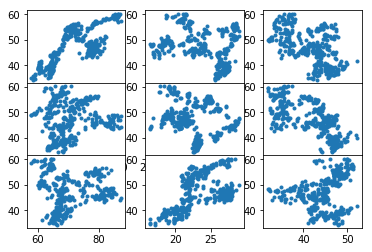

In [3]:
pylab.subplots_adjust(hspace=0)

for i in range(9):
    v = i+1
    ax1 = plt.subplot(3,3,v)
    ax1.plot(xTrain[:,i],sTrain,'.')

plt.show()

### b) Normalization:

With the aim of guaranteeing the numerical stability of subsequent sections, it is convenient to normalize the data. The fragment of code below implements a linear transformation so that the training data have zero mean and unit variance. Exactly the same transformation needs to be applied to validation and test data:


In [4]:
mx = np.mean(xTrain, 0)
stdx = np.std(xTrain,0)
xTrain = (xTrain - mx)/stdx 
xVal   = (xVal   - mx)/stdx
xTest  = (xTest  - mx)/stdx

## 2. Linear Regression: all features.

### a) Coefficients

Calculate the coefficients of minimum Mean Square Error (MSE) linear regression, based on the training data



In [5]:
# Linear Regression with the whole set of variables
xeTrain = np.insert(xTrain, 0, 1, axis=1)

we, resid, rank, s = np.linalg.lstsq(xeTrain, sTrain)
print(we)

[[ 47.14835526]
 [  4.71543755]
 [  1.9438805 ]
 [  0.23680584]
 [ -1.10817001]
 [  1.48285435]
 [ -3.38730085]
 [  0.95046007]
 [  1.08058746]
 [  2.19331668]]


### b) MSE

Compute the MSE measured over both the training and the test data sets.  

In [9]:
xeTest = np.insert(xTest, 0, 1, axis=1)
print xeTest.shape
print we.shape

sTestEst = np.dot(xeTest,we)
print sTestEst.shape
print sTest.shape

(190, 10)
(10, 1)
(190, 1)
(190, 1)


In [10]:
errorLTest  = np.mean((sTest - sTestEst)**2)
print(errorLTest)

6.12459136998


In [11]:
xeTest = np.insert(xTest, 0, 1, axis=1)

errorLTrain = np.mean((sTrain - xeTrain.dot(we))**2)
errorLTest  = np.mean((sTest - xeTest.dot(we))**2)

print('The train average square error is {0}'.format(errorLTrain))
print('The test average square error is {0}'.format(errorLTest))

The train average square error is 5.21451586908
The test average square error is 6.12459136998


### c) Coefficients

Compare these results to the MSE that would be obtained using “baseline” regression (i.e., without using any variables):  .


In [ ]:
# Linear Regression with the whole set of variables
xeTrain0 = xeTrain[:,0:1]
we, resid, rank, s = np.linalg.lstsq(xeTrain0, sTrain)
print('The baseline regression coefficient is {0}'.format(we[0][0]))

xeTest0 = xeTest[:, 0:1]

errorLTrain = np.mean((sTrain - xeTrain0.dot(we))**2)
errorLTest  = np.mean((sTest - xeTest0.dot(we))**2)

print('The train average square error is {0}'.format(errorLTrain))
print('The test average square error is {0}'.format(errorLTest))

### d) Feature selection. 

Obtain the MSEs (calculated over the training set) for the regression based in all possible subsets of features and select, for each value m ≤ 9, the best subset of `m` variables (i.e. the subset which provides a minimum MSE). Visualize the chosen variables for each value `m`.

In [ ]:
Dx = xTrain.shape[1]

Imax = 2**Dx
errorMin = float('Inf')*np.ones((Dx + 1, 1))
errorMinVal = errorMin
iMin = np.zeros(Dx+1, dtype='uint32')

for i in range(Imax):
    
    # Select variables
    variables = [n for n in range(Dx) if i & 2**n>0]
    
    # Training and validation sets
    xeTrain = xTrain[:,variables]
    xeTrain = np.insert(xeTrain, 0, 1, axis=1)
    xeVal = xVal[:,variables]
    xeVal = np.insert(xeVal, 0, 1, axis=1)

    # Regression
    we, resid, rank, s = np.linalg.lstsq(xeTrain, sTrain)
    error2Train = np.mean((sTrain - xeTrain.dot(we))**2)
    error2Val  = np.mean((sVal - xeVal.dot(we))**2)

    # Save variables if they beat the record for its number.
    num_bits = len(variables)     # No. of used variables
    if error2Train < errorMin[num_bits]: 
        errorMin[num_bits] = error2Train
        errorMinVal[num_bits] = error2Val
        iMin[num_bits] = i

# Determine matrix of selected variables
MatrizVar = np.zeros((Dx + 1, Dx));
for i in range(Dx + 1):
    MatrizVar[i] = [min(iMin[i] & 2**n, 1) for n in range(Dx)]

# Visualize the selected variables.
points = np.nonzero(MatrizVar)
i = points[0]
j = points[1] + 1
ax = plt.plot(i,j,'.', markersize=20)
plt.xlabel('Number of variables', fontsize=14)
plt.ylabel('Selected variables', fontsize=14)
plt.show()


### e) Average square error. 

Represent, as a function of the number of variables (m), their corresponding training and validation MSEs. 

In [ ]:
i = range(Dx+1)
markerline, stemlines, baseline = plt.stem(i, errorMin, '-', label='Train MSE')
plt.setp(markerline, 'markerfacecolor', 'b', 'markersize', 12)
plt.setp(stemlines, 'color', 'b')
plt.setp(baseline, 'color','r', 'linewidth', 2)

markerline, stemlines, baseline = pylab.stem(i, errorMinVal, '-', label='Validation MSE')
plt.setp(markerline, markerfacecolor='r', markersize=8)
plt.setp(stemlines, color='b')
plt.setp(baseline, color='r', linewidth=2)

plt.title('Linear regression with variable selection', fontsize=14)
plt.xlabel('Number of variables', fontsize=14);
plt.ylabel('Mean Square Error (MSE)', fontsize=14);
plt.legend();


## 3. Polynomial Regression with one variable

In this section we build polynomial regression models using variable `x1` only.  

### a) Polynomial regresion:

Study in detail the case of polynomial regression when using only one variable. Determine, for variable `x1`, the regression coefficients corresponding to the models of order 0 (no variables are used), 1 (linear), 2, …, 8, and plot the training MSE as a function of the degree of the polynomial.

In [ ]:
# Polynomial regression with variable x1.
GradoMax = 8;
Grados = range(GradoMax+1)

x1Train = xTrain[:,0]
x1Train = x1Train[:,np.newaxis]
nTrain = xTrain.shape[0]
xeTrain = np.empty(shape=[nTrain, 0])

errorPol = np.zeros(GradoMax+1)

for k in Grados:      # For every polynomial degree

    # Expand observations with polynomial terms
    Gradosk = Grados[0:k+1]
    xeTrain = np.append(xeTrain, x1Train**k, 1)

    # Regression
    we, resid, rank, s = np.linalg.lstsq(xeTrain, sTrain)
    errorPol[k] = np.mean((sTrain - xeTrain.dot(we))**2)

plt.plot(Grados, errorPol,':.',markersize=15);
plt.xlabel('Degree of the polynomial', fontsize=14)
plt.ylabel('Train MSE', fontsize=14)
plt.show()

### b) Regression function

Depict the regression function corresponding to the designed polynomial of degree 8.

In [ ]:
nPoints = 500;
xmin = min(x1Train)
xmax    = max(x1Train)
x = np.linspace(xmin, xmax, num=nPoints)
x = x[:, np.newaxis]

# Expand observations with polynomial terms
xe = np.empty(shape=[nPoints, 0])
for k in Grados:
    xe = np.append(xe, x**k, 1)

y = xe.dot(we)
plt.plot(x, y,'-')
plt.plot(x1Train,sTrain,'.')

plt.ylabel('$\hat{s}$', fontsize=14)
plt.xlabel('$x$', fontsize=14)
plt.xlim(xmin, xmax)
plt.show()

### b) Generalization.

In this subsection we will analyze the differences that are observed between the training and the validation MSEs. For this, compute again the corresponding regression coefficients using a subset of `K` samples randomly selected from the training data set; you could select, for instance, subsets of size `K` = 20, 40, 60, 80, 120, 140 and 160. 

#### b.1)  Average train and validation MSE

Plot for each value `K` the achieved training and validation MSEs as a function of the degree of the polynomial (in the range 0 to 9).  Given that the process of selecting `K` samples is random, it is convenient to average the previous MSEs over (at least) 1000 different selections of samples (for each `K`).

In [ ]:
### Parametros
n_sim = 1000   # Number of simulations to average
GradoMax = 9   # Maximum polynomial degree.
Grados = range(GradoMax+1) 
Nred = range(20, 161, 20)  # Size of the trainig set

### Expand all data (even though to all of them will be used.
x1Train = xTrain[:,0]
x1Val = xVal[:,0]
x1Test = xTest[:,0]

x1Train = x1Train[:,np.newaxis]
x1Val = x1Val[:, np.newaxis]
x1Test = x1Test[:, np.newaxis]

xeTrainFull = np.empty(shape=[nTrain, 0])
nVal = len(x1Val)
xeValFull = np.empty(shape=[nVal, 0])
nTest = len(x1Test)
xeTestFull = np.empty(shape=[nTest, 0])

# Expand observations with polynomial terms
for k in Grados:
    xeTrainFull = np.append(xeTrainFull, x1Train**k, 1)
    xeValFull = np.append(xeValFull, x1Val**k, 1)
    xeTestFull = np.append(xeTestFull, x1Test**k, 1)

errorRed = np.zeros((len(Nred), len(Grados)))
errorVal = np.zeros((len(Nred), len(Grados)))
errorTest = np.zeros((len(Nred), len(Grados)))

print("Please wait a minute. This can take some time ")

for i in range(len(Nred)):

    # This is just to print '.' without return (different in python 2 and 3)
    if sys.version_info.major == 2:
        print ".",
    else:
        print(".", end='')

    errorRedi = np.zeros((n_sim,len(Grados)))
    errorVali = np.zeros((n_sim,len(Grados)))
    errorTesti = np.zeros((n_sim,len(Grados)))


    for j in range(n_sim):

        # Select a training set at random
        ind = np.random.permutation(nTrain)
        xeRed = xeTrainFull[ind[range(Nred[i])], :]
        dRed = sTrain[ind[range(Nred[i])]];

        # Calculo de los errores de regresion polinomicos
        for k in Grados:
            Gradosk = Grados[0:k+1]
            xeRedk  = xeRed[:, 0:k+1]
            xeValk  = xeValFull[:, 0:k+1]
            xeTestk = xeTestFull[:, 0:k+1]

            # Regression
            we, resid, rank, s = np.linalg.lstsq(xeRedk, dRed)
            errorRedi[j,k] = np.mean((dRed - xeRedk.dot(we))**2)
            errorVali[j,k] = np.mean((sVal-xeValk.dot(we))**2)
            errorTesti[j,k] = np.mean((sTest-xeTestk.dot(we))**2)

    errorRed[i,:] = np.mean(errorRedi, axis=0)
    errorVal[i,:] = np.mean(errorVali, axis=0)
    errorTest[i,:] = np.mean(errorTesti, axis=0)

print(".")
ind = np.zeros((len(Grados),1))
ind[:,0] = Grados
for i in range(errorVal.shape[0]):
    plt.plot(ind, errorVal[i,:], '.-', markersize=16, label=str(Nred[i]))
    plt.plot(ind, errorRed[i,:], ':.', markersize=14)

plt.title('Training (dotted) and validation (continuous) MSE', fontsize=14)
plt.xlabel('Degree of the regression polynomial', fontsize=14)
plt.ylabel('MSE', fontsize=14)
plt.ylim(0, 100)
plt.legend()
print("The legend shows the number of samples used in each case")

#### b.2)  Model selection (degree optimization)

Using the figure you have just obtained, find, for each `K`, the degree of the polynomial obtaining the smallest MSE in the validation dataset, and depict such optimal degree as a function of `K`.

In [ ]:
# Compute the optimal polynomial degree
ErrorMin = np.min(errorVal, axis=1)
IndGradoOpt = np.argmin(errorVal, axis=1)
GradoOpt = [Grados[k] for k in IndGradoOpt]

plt.plot(Nred,GradoOpt,'.:', markersize=16)
plt.title('Model selection in polynomial regresion', fontsize=14)
plt.xlabel('Sample size of the training set', fontsize=14)
plt.ylabel('Optimal polynomial degree', fontsize=14)
plt.show()

#### b.3) Test MSE

Finally, represent graphically the test MSE, as a function of `K`, using the optimal degree (selected using the validation dataset) in each case.


In [ ]:
# Visualize test errors
ErrorOpt = np.zeros(len(Nred))
for i in range(len(Nred)):
   ErrorOpt[i] = errorTest[i,GradoOpt[i]]

plt.plot(Nred,ErrorOpt,'.:', markersize=16)
#stem(Nred,ErrorOpt,'filled'); hold off;
plt.title('Model selection in polynomial regresion', fontsize=14)
plt.xlabel('Sample size of the training set', fontsize=14)
plt.ylabel('Test error', fontsize=14)
plt.show()